# The estimator ladder: from historical simulation to GARCH, EVT, CAViaR and GAS-FZ

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (VaR, ES and a first exceedance count)
- **Reading time:** about 45 minutes

**Question:** Which rungs of the estimator ladder kept their 1 percent exceedance count near the expected one in six market windows, and what does each closed-form rung assume about the tail?

## Objectives

By the end of this notebook you can:

- name the rungs of the ladder of VaR and ES estimators Contraste runs, from historical simulation to the dynamic semiparametric models, and say what each one assumes;
- check from a committed artifact that every forecast was made with information dated before its day and that the hyperparameters were fixed before the windows they are scored on;
- run the closed-form rungs (age-weighted simulation, EWMA, delta-normal, Cornish-Fisher, filtered historical simulation and the peaks-over-threshold tail) on real returns with the engine's functions and set the EWMA path against the committed one;
- say which rungs cannot be refitted in a notebook and why, and read their convergence failures from the committed ladder;
- read, for six market windows, how often each rung exceeded its 1 percent VaR, and which rungs the eligibility gates removed.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data is case C11 as Contraste commits it: one document per market window plus the document of the ladder itself.

- `data/derived/C11/models-ladder.json`: the 18 entries of the ladder (17 fitted rungs and one challenger that was not run), each with its source, innovation, estimation window, refit frequency and, per window, the number of refits, convergence failures and the range of its fitted parameters.
- `data/derived/C11/<window>.json` for the six windows: `calm-2004-06`, `equity-2007-09`, `equity-2020`, `rates-2022`, `fx-2008` and `mixed-2023`. Each holds, for every model and tail level, the VaR and ES path, the exceedance days and the eligibility verdict.

Licence classes decide what is committed. Of the six windows only `rates-2022` and `fx-2008` commit the realised losses (Treasury and Federal Reserve H.10 data, `mirror-allowed`); the equity and mixed windows hold the Kenneth French return, `derived-only`, so they commit forecasts and exceedance days but not returns. The estimators cannot be refitted on a window whose estimation returns are not committed, and for no window are the 1,000 estimation days committed. The notebook therefore reads the committed forecasts of the fitted rungs and runs the closed-form rungs on the 251 realised returns of `fx-2008`, saying each time what that changes. The next cell loads the seven files.

In [2]:
# Load the ladder document and the six window documents (the notebook sits three folders below the
# repository root)
ROOT = Path("../../..").resolve()
C11 = ROOT / "data" / "derived" / "C11"
ladder_doc = json.loads((C11 / "models-ladder.json").read_text(encoding="utf-8"))
WINDOWS = ("calm-2004-06", "equity-2007-09", "equity-2020", "rates-2022", "fx-2008", "mixed-2023")
windows = {w: json.loads((C11 / f"{w}.json").read_text(encoding="utf-8")) for w in WINDOWS}
ladder = ladder_doc["fit"]["ladder"]
INNOVATION = {"empirical": "empirical", "normal": "normal", "student-t": "Student-t"}
INNOVATION.update({"gpd-tail": "GPD tail", "none": "none"})

print(f"{'model':11s} {'rung':5s} {'innovation':12s} {'days':>5s} {'refit':>7s}  estimator")
for entry in ladder:
    days = entry["estimation_window_days"] or "-"
    refit = entry["refit_every_days"] or "-"
    title = entry["title"]["en"]
    innovation = INNOVATION[entry["innovation"]]
    print(f"{entry['model_id']:11s} {entry['rung']:5s} {innovation:12s} {days!s:>5s} {refit!s:>7s}  {title}")
print("riskvalidation", ladder_doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)

model       rung  innovation    days   refit  estimator
hs-250      R1    empirical      250       1  Historical simulation, 250 days
hs-500      R1    empirical      500       1  Historical simulation, 500 days
awhs        R2    empirical      250       1  Age-weighted historical simulation
dn-rolling  R3    normal        1000       1  Delta-normal, rolling moments
cf-rolling  R3    normal        1000       1  Cornish-Fisher VaR, rolling moments
ewma        R4    normal        1000       1  EWMA (RiskMetrics)
garch-t     R5    Student-t     1000       1  GARCH(1,1) with Student-t innovations
gjr-t       R5    Student-t     1000       1  GJR-GARCH with Student-t innovations
egarch-t    R5    Student-t     1000       1  EGARCH with Student-t innovations
fhs         R6    empirical     1000       1  Filtered historical simulation
evt-mf      R7    GPD tail      1000       1  Conditional EVT (McNeil and Frey)
caviar-sav  R8    none          1000       5  CAViaR, symmetric absolute value
c

## Method

### Step 1: the ladder

A rung is one way of turning past returns into tomorrow's VaR and ES. The ladder runs from the transparent baseline to the current academic frontier, so a validator can ask of any complex rung whether it beats the simple one it replaces. The table printed above lists each rung with its number (R1 to R10), the distribution it assumes for the innovations, how many past days it reads and how often it is refitted. Three families matter for what follows: the empirical rungs (R1, R2 and R6) read the shape of the tail from the data, the normal rungs (R3 and R4) assume it, and the dynamic rungs (R5, R8 and R9) let the volatility or the quantile itself move with the data. The last entry, `nn-fz`, is a neural challenger of the literature that the bake does **not** train; the document says so instead of leaving it out.

### Step 2: no look-ahead, hyperparameters fixed in advance

Two rules make a back-test honest. First, every forecast uses only returns dated **before** its day: each window document records, for each forecast date, the first and last day of the estimation sample (`grid.estimation_start`, `grid.estimation_end`). Second, the hyperparameters (the EWMA decay, the age-weighting decay, the EVT threshold fraction, the number of optimiser starts) are chosen on a span that ends before every window starts, never on the window being scored (`hyperparameters.fixed_on`, `tuned_on_test_window`). Both rules are checkable from the committed file, which the next cell does for the six windows.

In [3]:
# Check the two rules of an honest back-test on every window: the estimation sample ends before its day,
# hyperparameters first
SCHEME = {"rolling": "rolling", "expanding": "expanding"}
print(f"{'window':15s} {'scheme':>22s} {'sample ends before its day':>8s} {'hyperparameters fixed on'}")
for w, doc in windows.items():
    grid, hyper = doc["outputs"]["grid"], doc["outputs"]["hyperparameters"]
    before = all(end < day for end, day in zip(grid["estimation_end"], grid["dates"]))
    fixed = hyper["fixed_on"]
    print(f"{w:15s} {SCHEME[grid['scheme']]} {grid['estimation_window_days']:>5d} | {'yes' if before else 'no'} | "
          f"{fixed['start']} to {fixed['end']} | tuned on the test window: "
          f"{'yes' if hyper['tuned_on_test_window'] else 'no'}")

window                          scheme sample ends before its day hyperparameters fixed on
calm-2004-06    rolling  1000 | yes | 1995-01-01 to 2003-12-31 | tuned on the test window: no
equity-2007-09  rolling  1000 | yes | 1995-01-01 to 2003-12-31 | tuned on the test window: no
equity-2020     rolling  1000 | yes | 1995-01-01 to 2003-12-31 | tuned on the test window: no
rates-2022      rolling  1000 | yes | 1995-01-01 to 2003-12-31 | tuned on the test window: no
fx-2008         rolling  1000 | yes | 1995-01-01 to 2003-12-31 | tuned on the test window: no
mixed-2023      rolling  1000 | yes | 1995-01-01 to 2003-12-31 | tuned on the test window: no


### Step 3: age-weighted historical simulation (rung R2)

Plain historical simulation gives every day of the window the same weight, so a crisis day leaves the window all at once and the VaR jumps. Boudoukh, Richardson and Whitelaw (1998) weight the return observed $i$ days ago by

$$w_i = \frac{1-\lambda}{1-\lambda^{K}}\,\lambda^{\,i-1}, \qquad i = 1,\dots,K$$

sort the returns, accumulate the weights until they reach $\alpha$, and interpolate. The engine's `age_weights(lam, k)` returns the weights and `age_weighted_var_es(returns, alpha, lam, window)` the forecast; the ES is the tail integral of the same interpolated quantile function (the paper gives no ES rule, the engine documents this as its decision D-9). We use the committed $\lambda$ and the first 100 returns of `fx-2008`, which is a shorter window than the committed $K = 250$, and compare with the equally weighted forecast at the 2.5 percent level, where the tail holds 2.5 observations.

lambda 0.99, K 100: newest 0.01577 | oldest 0.00583
effective days 1 / sum(w^2): 92.4
alpha 0.01: equal VaR 0.022293 ES 0.022293 | age VaR 0.022072 ES 0.022246
alpha 0.025: equal VaR 0.020861 ES 0.021771 | age VaR 0.021324 ES 0.021933


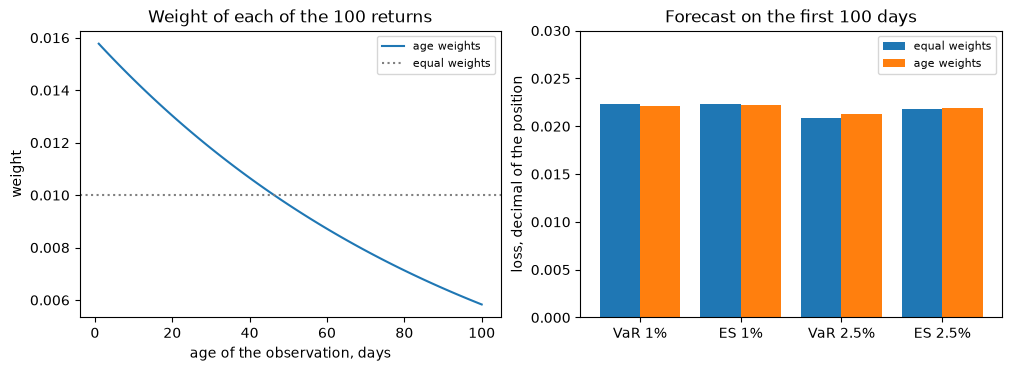

In [4]:
# Age weights with the committed decay, and the age-weighted forecast against the equally weighted one on
# 100 returns
from riskvalidation.market.historical import age_weighted_var_es, age_weights, historical_var_es

fx_out = windows["fx-2008"]["outputs"]
y = -np.array(fx_out["grid"]["realised_loss"]["loss"])
lam_age = fx_out["hyperparameters"]["age_weight_lambda"]
K = 100
weights = age_weights(lam_age, K)
print(f"lambda {lam_age}, K {K}: newest {weights[0]:.5f} | oldest {weights[-1]:.5f}")
print(f"effective days 1 / sum(w^2): {1 / np.sum(weights ** 2):.1f}")

values = {"equal": [], "aged": []}
for alpha in (0.01, 0.025):
    equal = historical_var_es(y[:K], alpha, K)
    aged = age_weighted_var_es(y[:K], alpha, lam_age, K)
    values["equal"] += [-equal[0], -equal[1]]
    values["aged"] += [-aged[0], -aged[1]]
    print(f"alpha {alpha}: equal VaR {-equal[0]:.6f} ES {-equal[1]:.6f} | age VaR {-aged[0]:.6f} ES {-aged[1]:.6f}")

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
left.plot(np.arange(1, K + 1), weights, label="age weights")
left.axhline(1 / K, color="grey", linestyle=":", label="equal weights")
left.set_xlabel("age of the observation, days")
left.set_ylabel("weight")
left.set_title("Weight of each of the 100 returns")
left.legend(fontsize=8)
for shift, (name, label) in zip((-0.2, 0.2), (("equal", "equal weights"), ("aged", "age weights"))):
    right.bar(np.arange(4) + shift, values[name], width=0.4, label=label)
right.set_xticks(np.arange(4), ["VaR 1%", "ES 1%", "VaR 2.5%", "ES 2.5%"])
right.set_ylim(0, 0.03)
right.set_ylabel("loss, decimal of the position")
right.set_title("Forecast on the first 100 days")
right.legend(fontsize=8)
plt.show()

The left panel shows the weight of each of the 100 returns, from 0.01577 for the newest to 0.00583 for the oldest, against the 0.010 of equal weighting; the effective number of days is 92.4 of 100, so the decay changes little on a window this short. The right panel shows where the choice of weights does bite: at the 1 percent level the equally weighted VaR and ES are both 0.022293, because the tail holds a single observation, while age weighting spreads the tail over two returns and gives an ES of 0.022246 slightly above its VaR of 0.022072. At 2.5 percent it lifts the VaR from 0.020861 to 0.021324. The figure does not show that age weighting is better, only that it moves the tail estimate by about two percent here; whether it helps is a question for the exceedance counts of the last figure.

### Step 4: EWMA, the volatility that reacts (rung R4)

RiskMetrics models the variance of tomorrow's return as an exponentially weighted average of squared returns, with a zero mean (the zero mean is part of the method):

$$\sigma^2_{t+1\mid t} = \lambda\,\sigma^2_{t\mid t-1} + (1-\lambda)\,r_t^2, \qquad K = \frac{\ln \varepsilon}{\ln \lambda}$$

where $K$ is the number of days that carry a weight above the tolerance $\varepsilon$ (RiskMetrics Technical Document, section 5.3.2). The VaR and ES then come from the normal distribution with that variance (delta-normal, rung R3):

$$v = \mu + \Phi^{-1}(\alpha)\,\sigma, \qquad e = \mu - \sigma\,\frac{\varphi(\Phi^{-1}(\alpha))}{\alpha}$$

The cell runs the engine's `ewma_variance` on the 251 realised returns with the committed decay $\lambda$, started from the variance of the first 20 returns, turns each forecast volatility into a 1 percent VaR with `delta_normal_var_es` and counts how often that VaR was exceeded. The figure sets the recomputed path beside the committed `ewma` VaR and the committed `hs-250` VaR.

lambda 0.97 | days with a weight above 1%: 151.2
sigma: first day 0.004846 | last day 0.008828 | largest 0.014615
exceedances of the 1% VaR: 3 | expected 2.51


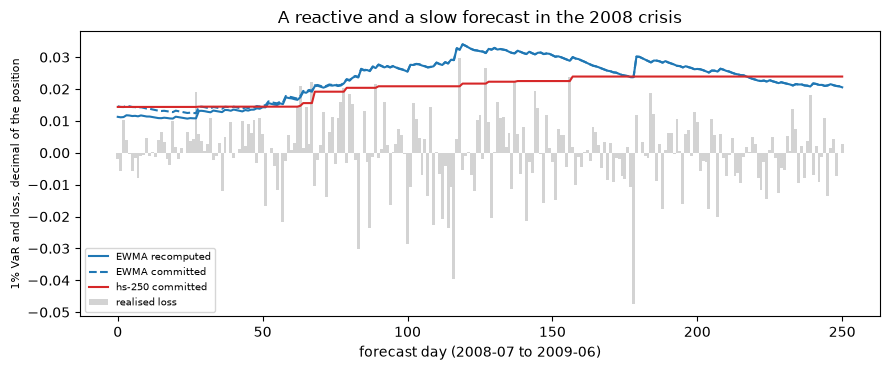

In [5]:
# EWMA volatility from the engine, started on the first 20 returns, the 1% delta-normal VaR it implies and
# its exceedances
from riskvalidation.market.parametric import delta_normal_var_es, ewma_effective_days, ewma_variance

lam = fx_out["hyperparameters"]["ewma_lambda"]
sigma = np.sqrt(ewma_variance(y[:-1], lam, float(np.var(y[:20]))))
var_ewma = np.array([-delta_normal_var_es(0.0, s, 0.01)[0] for s in sigma])
loss = -y
print(f"lambda {lam} | days with a weight above 1%: {ewma_effective_days(lam, 0.01):.1f}")
print(f"sigma: first day {sigma[0]:.6f} | last day {sigma[-1]:.6f} | largest {sigma.max():.6f}")
print(f"exceedances of the 1% VaR: {int((loss > var_ewma).sum())} | expected {0.01 * y.size:.2f}")

models = {m["model_id"]: m for m in fx_out["models"]}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(np.arange(y.size), loss, color="lightgrey", width=1.0, label="realised loss")
ax.plot(var_ewma, color="tab:blue", label="EWMA recomputed")
ax.plot(models["ewma"]["by_level"][0]["var"], color="tab:blue", linestyle="--", label="EWMA committed")
ax.plot(models["hs-250"]["by_level"][0]["var"], color="tab:red", label="hs-250 committed")
ax.set_xlabel("forecast day (2008-07 to 2009-06)")
ax.set_ylabel("1% VaR and loss, decimal of the position", fontsize=8)
ax.set_title("A reactive and a slow forecast in the 2008 crisis")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

The recomputed EWMA path (solid blue) starts below the committed one (dashed) because its initial variance comes from only 20 returns, and it joins the committed path within about 30 days; from then on the two lines are indistinguishable, so the committed rung and the engine's function describe the same recursion. The forecast volatility climbs from 0.004846 on the first day to a maximum of 0.014615 and the VaR follows it up to about 0.034, while the committed `hs-250` VaR (red) stays near 0.015 for two months and then moves in steps, one for each exceedance. EWMA counts 3 exceedances of its 1 percent VaR against 2.51 expected. The figure does not show the cost of reactivity: after the peak the EWMA VaR falls back, and with a decay of 0.97 the forecast forgets a crisis in about 151.2 days.

### Step 5: Cornish-Fisher (rung R3)

The delta-normal rung under-covers when returns have fat tails or skew. The Cornish-Fisher expansion corrects the normal quantile $z = \Phi^{-1}(\alpha)$ with the skewness $S$ and the excess kurtosis $K_e$ of the returns:

$$z_{CF} = z + \frac{(z^2-1)S}{6} + \frac{(z^3-3z)K_e}{24} - \frac{(2z^3-5z)S^2}{36}, \qquad v = \mu + z_{CF}\,\sigma$$

The expansion is not monotone for large $S$ and $K_e$, so a forecast must report whether it is in its validity domain; the engine's `cornish_fisher_var` returns `valid`. It gives a VaR and no ES, which is why the committed `cf-rolling` has no FZ0 score (notebook 05). We compare the three VaR estimates on the sample moments of the 251 returns.

mean -0.000407 | standard deviation 0.010608 | skewness 0.629 | excess kurtosis 2.129
alpha 0.01: z -2.326 -> z_CF -2.212 | valid expansion: yes
  VaR normal 0.025085 | Cornish-Fisher 0.023873 | empirical 0.023915
alpha 0.025: z -1.960 -> z_CF -1.750 | valid expansion: yes
  VaR normal 0.021198 | Cornish-Fisher 0.018974 | empirical 0.020861


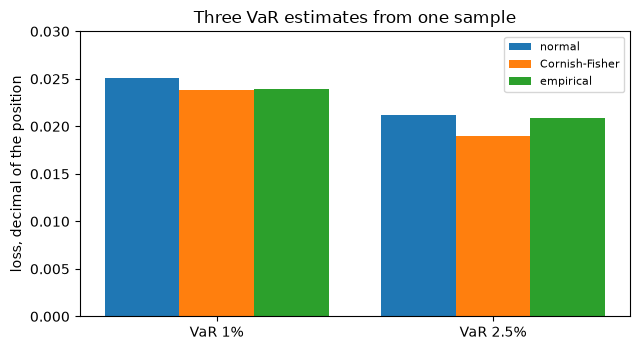

In [6]:
# Cornish-Fisher VaR from the sample moments against delta-normal and the empirical quantile, at both tail
# levels
from riskvalidation.market.conventions import var_es_from_sample
from riskvalidation.market.parametric import cornish_fisher_var

mu, sd = float(y.mean()), float(y.std())
skew, excess = float(stats.skew(y)), float(stats.kurtosis(y))
print(f"mean {mu:.6f} | standard deviation {sd:.6f} | skewness {skew:.3f} | "
      f"excess kurtosis {excess:.3f}")
estimates = []
for alpha in (0.01, 0.025):
    cf = cornish_fisher_var(mu, sd, skew, excess, alpha)
    normal = delta_normal_var_es(mu, sd, alpha)
    empirical = var_es_from_sample(y, alpha)
    estimates.append((-normal[0], -cf.var, -empirical[0]))
    print(f"alpha {alpha}: z {stats.norm.ppf(alpha):.3f} -> z_CF {cf.z_cf:.3f} | valid expansion: "
          f"{'yes' if cf.valid else 'no'}")
    print(f"  VaR normal {-normal[0]:.6f} | Cornish-Fisher {-cf.var:.6f} | empirical {-empirical[0]:.6f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for k, name in enumerate(("normal", "Cornish-Fisher", "empirical")):
    ax.bar(np.arange(2) + (k - 1) * 0.27, [row[k] for row in estimates], width=0.27, label=name)
ax.set_xticks(np.arange(2))
ax.set_xticklabels(["VaR 1%", "VaR 2.5%"])
ax.set_ylim(0, 0.03)
ax.set_ylabel("loss, decimal of the position")
ax.set_title("Three VaR estimates from one sample")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The returns are right-skewed (0.629) and have an excess kurtosis of 2.129, so their tails are heavier than the normal's even though the skew favours the long position. The Cornish-Fisher correction answers by shrinking the loss quantile: at 1 percent it takes the normal VaR of 0.025085 to 0.023873, almost exactly the empirical 0.023915, and at 2.5 percent it overshoots, 0.018974 against an empirical 0.020861 and a normal 0.021198. The expansion was valid at both levels. The figure shows a moment fit that happens to match at one level and misses at the other; it is a correction of the normal, not a better model of the tail, and with 251 days the skewness and kurtosis it feeds on are themselves noisy.

### Step 6: filtered historical simulation and the peaks-over-threshold tail (rungs R6 and R7)

Both rungs first **filter** the returns, dividing each by the volatility forecast made before it, $z_t = r_t/\sigma_t$, so the standardised residuals are close to identically distributed. Filtered historical simulation (Barone-Adesi, Giannopoulos and Vosper, 1999) then rescales those residuals with tomorrow's volatility, $r^*_s = \mu_{T+1} + \sigma_{T+1} z_s$, and reads the VaR and ES of the scenarios. Conditional EVT (McNeil and Frey, 2000) instead fits a generalised Pareto distribution to the excesses of the loss residuals $-z_t$ above a threshold $u$ (the $1-f$ quantile) and extrapolates; with $N_u$ exceedances out of $n$ and $q = 1-\alpha$,

$$\hat z_q = u + \frac{\hat\beta}{\hat\xi}\left[\left(\tfrac{n}{N_u}(1-q)\right)^{-\hat\xi} - 1\right], \qquad \widehat{\mathrm{ES}}_q = \frac{\hat z_q}{1-\hat\xi} + \frac{\hat\beta - \hat\xi u}{1-\hat\xi} \quad (\hat\xi<1)$$

The committed rungs filter with a GARCH model fitted on 1,000 estimation days that are not committed, so they cannot be refitted here. The filter of this cell is the EWMA volatility of step 4, which exercises the same engine functions (`filtered_hs_var_es`, `fit_gpd`, `evt_var_es`) on real residuals; the numbers are those of an EWMA-filtered rung on 251 days, not of the committed `fhs` or `evt-mf`. The cell standardises the returns, fits the tail at the committed threshold fraction and prints the next-day VaR and ES of the three estimators.

In [7]:
# Standardise the returns with the EWMA volatility, fit the GPD tail and forecast the next day with three
# estimators
from riskvalidation.market.evt import evt_var_es, fit_gpd
from riskvalidation.market.historical import filtered_hs_var_es

residuals = y / sigma
fraction = fx_out["hyperparameters"]["evt_threshold_fraction"]
tail = fit_gpd(-residuals, fraction)
print(f"standardised residuals: mean {residuals.mean():.3f} | "
      f"standard deviation {residuals.std():.3f} | minimum {residuals.min():.3f}")
print(f"GPD threshold fraction {fraction}: u {tail.threshold:.3f}, xi {tail.xi:.3f}, beta {tail.beta:.3f}, "
      f"{tail.n_exceed} exceedances of {tail.n}")
for alpha in (0.01, 0.025):
    fhs = filtered_hs_var_es(residuals, 0.0, sigma[-1], alpha)
    z_q, es_q = evt_var_es(tail, 1.0 - alpha)
    normal = delta_normal_var_es(0.0, sigma[-1], alpha)
    print(f"alpha {alpha}: VaR (ES) | normal {-normal[0]:.5f} ({-normal[1]:.5f}) | "
          f"filtered HS {-fhs[0]:.5f} ({-fhs[1]:.5f}) | EVT {sigma[-1] * z_q:.5f} ({sigma[-1] * es_q:.5f})")

standardised residuals: mean -0.077 | standard deviation 1.105 | minimum -4.127
GPD threshold fraction 0.05: u 1.904, xi 0.474, beta 0.235, 13 exceedances of 251
alpha 0.01: VaR (ES) | normal 0.02054 (0.02353) | filtered HS 0.02389 (0.02918) | EVT 0.02198 (0.03060)
alpha 0.025: VaR (ES) | normal 0.01730 (0.02064) | filtered HS 0.01859 (0.02349) | EVT 0.01861 (0.02420)


The shape $\hat\xi$ of the tail is the number an EVT forecast depends on, and it depends on the threshold fraction the validator picks. The next cell refits the tail at five fractions with the engine's `threshold_stability` and draws the shape and the number of exceedances it rests on.

threshold fraction 0.04 | xi   0.513 | exceedances 10
threshold fraction 0.05 | xi   0.474 | exceedances 13
threshold fraction 0.06 | xi   0.202 | exceedances 15
threshold fraction 0.08 | xi   0.135 | exceedances 20
threshold fraction 0.10 | xi  -0.036 | exceedances 25


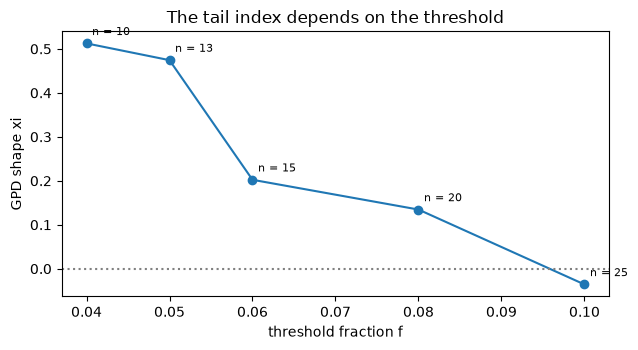

In [8]:
# Refit the GPD tail at five threshold fractions and draw the shape parameter with the exceedances it rests on
from riskvalidation.market.evt import threshold_stability

table = threshold_stability(-residuals, np.array([0.04, 0.05, 0.06, 0.08, 0.10]))
for fraction_i, xi, n_exceed in table:
    print(f"threshold fraction {fraction_i:.2f} | xi {xi:7.3f} | exceedances {n_exceed}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot([row[0] for row in table], [row[1] for row in table], marker="o")
for fraction_i, xi, n_exceed in table:
    ax.annotate(f"n = {n_exceed}", (fraction_i, xi), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.axhline(0, color="grey", linestyle=":")
ax.set_xlabel("threshold fraction f")
ax.set_ylabel("GPD shape xi")
ax.set_title("The tail index depends on the threshold")
fig.tight_layout()
plt.show()

The shape runs from 0.513 with 10 exceedances to -0.036 with 25, so the tail index changes sign inside the range of thresholds a practitioner would try, and with 251 days a 5 percent threshold leaves 13 exceedances. A positive shape means a heavy tail with no upper bound on the loss and a negative one a bounded tail, so the choice of threshold decides which story the forecast tells. The table above shows the consequence for the forecast: the next-day 1 percent VaR is 0.02054 under the normal, 0.02389 by filtered historical simulation and 0.02198 by EVT, but the ES is 0.02353, 0.02918 and 0.03060, a 30 percent spread from the lowest to the highest. The ES is where the tail model matters, and the threshold fraction is a hyperparameter the validator has to fix before the window, as step 2 checked.

### Step 7: the rungs that cannot be refitted here, and how their fits behaved

Three families need more than a notebook can reproduce from committed files, and the document of the ladder is the evidence for them.

- **GARCH family (R5):** $\sigma_t^2 = \omega + \alpha_1\varepsilon_{t-1}^2 + \beta_1\sigma_{t-1}^2$ (Bollerslev, 1986), with a leverage term $\gamma\,\mathbb 1\{\varepsilon_{t-1}<0\}\varepsilon_{t-1}^2$ in GJR (Glosten, Jagannathan and Runkle, 1993) and $\ln\sigma_t^2 = \omega + \beta\ln\sigma_{t-1}^2 + \theta z_{t-1} + \gamma(|z_{t-1}| - E|z|)$ in EGARCH (Nelson, 1991), all with Student-t innovations. The engine fits them through the optional package `arch`.
- **CAViaR (R8):** the VaR itself follows a recursion, for example $f_t = b_1 + b_2 f_{t-1} + b_3 |y_{t-1}|$ (Engle and Manganelli, 2004), fitted by minimising the tick loss from several starts; `caviar-es` adds an autoregressive gap below the VaR (Taylor, 2019), estimated in two steps, a declared deviation from Taylor's joint estimation. The engine's `fit_caviar` requires at least 500 returns.
- **GAS-FZ (R9):** the pair (VaR, ES) follows a score-driven recursion fitted by minimising the average FZ0 loss (Patton, Ziegel and Chen, 2019); `fit_gas_fz` also requires at least 500 returns. Notebook 07 returns to these.

No window commits 500 estimation returns, so the notebook does not refit them. What the ladder records is how the fits behaved: the number of refits and of convergence failures per rung and window. The figure shows the share of refits that did not converge for the rungs that are fitted by optimisation.

largest share: garch-t in mixed-2023, 73.4%
median parameters equity-2007-09, garch-t: {'alpha[1]': 0.0596, 'beta[1]': 0.9195, 'mu': 0.0007, 'nu': 8.4689, 'omega': 0.0}
median parameters equity-2007-09, gjr-t: {'alpha[1]': 0.0, 'beta[1]': 0.9207, 'gamma[1]': 0.1167, 'mu': 0.0004, 'nu': 9.0724, 'omega': 0.0}
median parameters equity-2007-09, egarch-t: {'alpha[1]': 0.045, 'beta[1]': 0.9801, 'gamma[1]': -0.1529, 'mu': 0.0004, 'nu': 8.4864, 'omega': -0.1956}


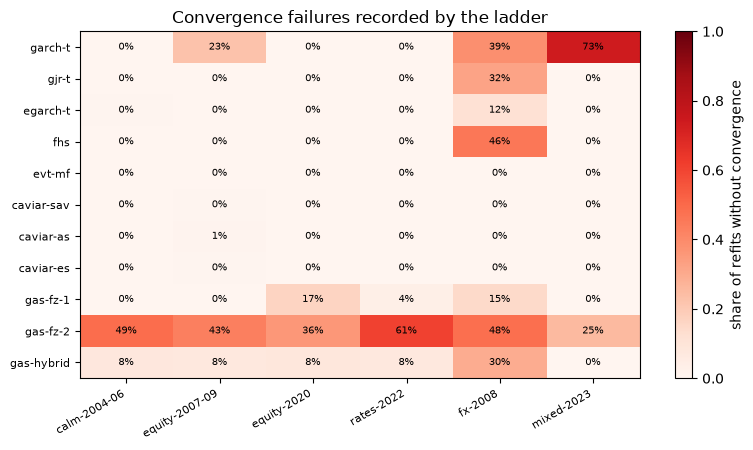

In [9]:
# Share of refits that did not converge, per rung and window, drawn as a heat map, and the median GARCH
# parameters
fits = {e["model_id"]: {wf["window_id"]: wf for wf in e["window_fits"]} for e in ladder if e["window_fits"]}
fitted = ["garch-t", "gjr-t", "egarch-t", "fhs", "evt-mf", "caviar-sav", "caviar-as", "caviar-es"]
fitted += ["gas-fz-1", "gas-fz-2", "gas-hybrid"]
share = np.array([[fits[m][w]["n_convergence_failures"] / fits[m][w]["n_refits"] for w in WINDOWS] for m in fitted])
worst = np.unravel_index(share.argmax(), share.shape)
print(f"largest share: {fitted[worst[0]]} in {WINDOWS[worst[1]]}, {share.max():.1%}")
for m in ("garch-t", "gjr-t", "egarch-t"):
    params = {p["name"]: round(p["median"], 4) for p in fits[m]["equity-2007-09"]["parameters"]}
    print(f"median parameters equity-2007-09, {m}: {params}")

fig, ax = plt.subplots(figsize=(8, 4.6))
image = ax.imshow(share, cmap="Reds", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(WINDOWS)))
ax.set_xticklabels(WINDOWS, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(fitted)))
ax.set_yticklabels(fitted, fontsize=8)
for i in range(len(fitted)):
    for j in range(len(WINDOWS)):
        ax.text(j, i, f"{share[i, j]:.0%}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="share of refits without convergence")
ax.set_title("Convergence failures recorded by the ladder")
fig.tight_layout()
plt.show()

The darkest cell is GARCH-t in `mixed-2023`, where 73.4 percent of the refits did not converge, and the whole `gas-fz-2` row is shaded: between a quarter and 61 percent of its fits fail in every window. CAViaR and the EVT rung almost never fail (0 to 1 percent), and filtered historical simulation inherits the failures of the GARCH filter it runs on, 46 percent in `fx-2008`. The median parameters of the equity crisis (GARCH-t alpha 0.0596, beta 0.9195, nu 8.4689) describe a persistent, heavy-tailed process, but a median taken over fits that include failed ones is only as reliable as the failure share beside it. The figure records how the optimiser behaved; it does not say what the pipeline did with a failed refit, which is why these rungs are judged by their forecasts and not by their fits.

### Step 8: the whole ladder against six windows

The final table puts every rung's 1 percent exceedance count beside the count expected from the binomial, in each window, and marks the rungs the eligibility gates removed (Kupiec, conditional coverage or the Acerbi-Szekely test red at either level; the gates are the subject of notebooks 03 and 04). A ratio near 1 is a forecast of the right size; a ratio far above 1 under-covers. The heat map draws the same ratios. `mixed-2023` expects only 0.6 exceedances in 64 days, so every rung has a count of 0 and the window cannot separate the rungs by coverage.

expected exceedances per window: [7.5, 5.0, 1.0, 2.5, 2.5, 0.6]
rungs removed by the gates per window: [6, 17, 13, 13, 7, 0] of 17
equity-2007-09: range of counts 13 to 57


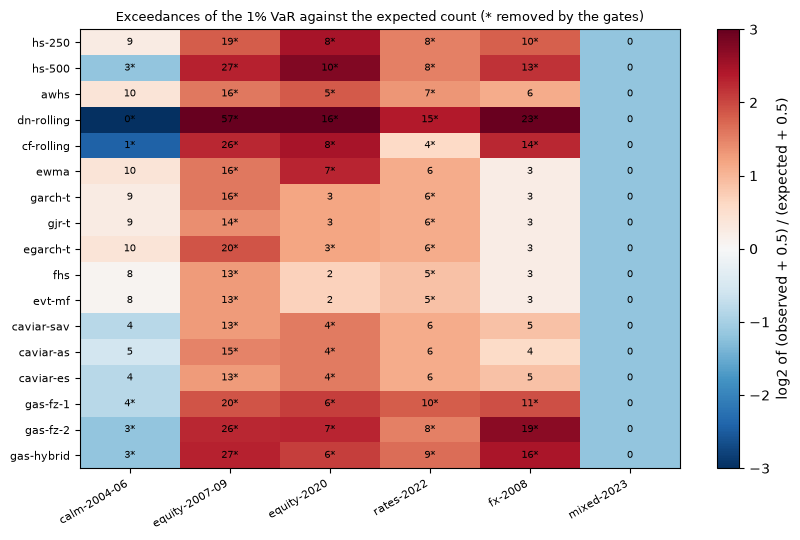

In [10]:
# Exceedances of the 1% VaR against the expected count for every rung and window, drawn as a heat map of the
# ratio
rungs = [m["model_id"] for m in windows["fx-2008"]["outputs"]["models"]]
counts = np.zeros((len(rungs), len(WINDOWS)))
expected = np.zeros(len(WINDOWS))
removed = np.zeros((len(rungs), len(WINDOWS)), dtype=bool)
for j, w in enumerate(WINDOWS):
    for i, model in enumerate(windows[w]["outputs"]["models"]):
        level = model["by_level"][0]
        counts[i, j], expected[j] = level["n_exceedances"], level["expected_exceedances"]
        removed[i, j] = not model["eligible"]
print("expected exceedances per window:", expected.round(1).tolist())
print("rungs removed by the gates per window:", removed.sum(axis=0).tolist(), "of", len(rungs))
print("equity-2007-09: range of counts", int(counts[:, 1].min()), "to", int(counts[:, 1].max()))

ratio = (counts + 0.5) / (expected + 0.5)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
image = ax.imshow(np.log2(ratio), cmap="RdBu_r", vmin=-3, vmax=3, aspect="auto")
ax.set_xticks(range(len(WINDOWS)))
ax.set_xticklabels(WINDOWS, rotation=30, ha="right", fontsize=8)
ax.set_yticks(range(len(rungs)))
ax.set_yticklabels(rungs, fontsize=8)
for i in range(len(rungs)):
    for j in range(len(WINDOWS)):
        ax.text(j, i, f"{int(counts[i, j])}{'*' if removed[i, j] else ''}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="log2 of (observed + 0.5) / (expected + 0.5)")
ax.set_title("Exceedances of the 1% VaR against the expected count (* removed by the gates)", fontsize=9)
fig.tight_layout()
plt.show()

Red cells exceed the expected count, blue cells fall short of it, and a star marks a rung the gates removed. In `equity-2007-09` every rung is red and starred, with 13 to 57 exceedances against 5.0 expected. In the calm window the removals go the other way: `dn-rolling` has 0 exceedances against 7.5 and the GAS-FZ rungs 3 to 4, so the gates also catch forecasts that are too cautious. In `fx-2008` the EWMA, the three GARCH, filtered historical simulation and EVT sit at 3 exceedances against 2.5 expected and survive, while the three GAS-FZ rungs have 11, 19 and 16. In `mixed-2023` no rung has an exceedance in 64 days (0.6 expected), so that column cannot separate the rungs by coverage. In the five windows where a count can separate them no rung passes the gates in all of them, and the best ones pass in three.

## Results

**Answer:** No rung kept its count near the expected one in every window. The eligibility gates removed 6, 17, 13, 13, 7 and 0 of the 17 rungs in the six windows; in `equity-2007-09` the counts ran from 13 to 57 exceedances against 5.0 expected, and the rungs that did best elsewhere (EWMA, the CAViaR variants, GARCH-t, filtered historical simulation and EVT) passed the gates in only three of the five windows where a count can separate them.

- **The ladder.** It has 18 entries: 17 fitted rungs from historical simulation (R1) to the GAS-FZ models (R9), and `nn-fz` (R10), a neural challenger the bake records as not run. Nothing in the committed data says a neural model was evaluated.
- **No look-ahead.** In all six windows every estimation sample ends before its forecast day, and the hyperparameters were fixed on 1995-01-01 to 2003-12-31, before every window, with the test window never used to tune them.
- **Age weighting and the tail.** With a decay of 0.99 and 100 days the effective number of days is 92.4. At 2.5 percent the equally weighted forecast is 0.020861 for the VaR and 0.021771 for the ES, the age-weighted 0.021324 and 0.021933. At 1 percent the tail is one observation, so for equal weights the ES equals the VaR (0.022293 both): an ES needs a tail with several observations.
- **EWMA reacts.** With a decay of 0.97 the weight falls under 1 percent after 151.2 days. The volatility rises from 0.004846 to 0.014615 in the crisis, and the EWMA VaR has 3 exceedances against 2.51 expected, which a fixed 250-day window could not do.
- **Normal, Cornish-Fisher and the sample.** The returns have a skewness of 0.629 and an excess kurtosis of 2.129. At 1 percent the VaR is 0.025085 under the normal, 0.023873 with Cornish-Fisher and 0.023915 empirically; at 2.5 percent 0.021198, 0.018974 and 0.020861. The correction helps at one level and overshoots at the other.
- **Filtered simulation and EVT on EWMA residuals.** The standardised residuals have a standard deviation of 1.105 and a minimum of -4.127. At 1 percent the next-day VaR (ES) is 0.02054 (0.02353) normal, 0.02389 (0.02918) filtered historical simulation and 0.02198 (0.03060) EVT. The GPD shape depends on the threshold, 0.513 with 10 exceedances and -0.036 with 25, so the tail index changes sign inside the range a practitioner would try.
- **The fits that cannot be repeated here.** GARCH-t did not converge in 73.4 percent of its refits in `mixed-2023`, and the two-factor GAS-FZ failed in every window. CAViaR and EVT almost never fail. The estimators with a recursion need at least 500 returns and no window commits them.

What this notebook does not show: whether a count is statistically compatible with its expected value (notebook 03), the ES forecasts (notebook 04), or which eligible rung forecasts best (notebook 05).

## Summary

- The ladder is a sequence of estimators with a known source, innovation and refit schedule; the committed document also records the challenger it does not run.
- Two properties of an honest back-test are checkable from the committed files: every estimation sample ends before its forecast day, and the hyperparameters were fixed before every window.
- The closed-form rungs run on real returns with the engine's functions: age weighting moves the tail estimate by a couple of percent, EWMA follows a crisis that a 250-day window learns in steps, Cornish-Fisher is a moment fit that matches at one level and misses at the other, and the EVT shape depends on a threshold the validator must fix in advance.
- GARCH, CAViaR and GAS-FZ need a package or a sample size a notebook on committed files does not have; their evidence is the committed forecasts and the record of their refits and convergence failures.
- No rung wins everywhere: coverage depends on the window, and the gates remove many rungs in the crisis windows.

**What to try next.** Change the decay of the EWMA cell to 0.94 and count the exceedances of the recomputed VaR again; then read notebook 03 to see how the exceedance counts above are tested.

## References

- Pritsker, M. (2001), The hidden dangers of historical simulation, Federal Reserve Board FEDS 2001-27. https://www.federalreserve.gov/Pubs/feds/2001/200127/200127pap.pdf
- Boudoukh, J., Richardson, M. and Whitelaw, R. (1998), The best of both worlds, Risk 11(5). https://pages.stern.nyu.edu/~rwhitela/papers/hybrid%20risk98.pdf
- J.P. Morgan/Reuters (1996), RiskMetrics Technical Document, 4th ed., section 5.3.2. https://www.msci.com/documents/10199/5915b101-4206-4ba0-aee2-3449d5c7e95a
- Cornish, E. A. and Fisher, R. A. (1938), Moments and cumulants in the specification of distributions, Revue de l'Institut International de Statistique 5(4). https://doi.org/10.2307/1400905
- Bollerslev, T. (1986), Generalized autoregressive conditional heteroskedasticity, Journal of Econometrics 31(3). https://doi.org/10.1016/0304-4076(86)90063-1
- Glosten, L. R., Jagannathan, R. and Runkle, D. E. (1993), On the relation between the expected value and the volatility of the nominal excess return on stocks, Journal of Finance 48(5). https://doi.org/10.1111/j.1540-6261.1993.tb05128.x
- Nelson, D. B. (1991), Conditional heteroskedasticity in asset returns: a new approach, Econometrica 59(2). https://doi.org/10.2307/2938260
- McNeil, A. J. and Frey, R. (2000), Estimation of tail-related risk measures for heteroscedastic financial time series: an extreme value approach, Journal of Empirical Finance 7(3-4). https://doi.org/10.1016/S0927-5398(00)00012-8
- Engle, R. F. and Manganelli, S. (2004), CAViaR: conditional autoregressive value at risk by regression quantiles, Journal of Business and Economic Statistics 22(4). https://doi.org/10.1198/073500104000000370
- Taylor, J. W. (2019), Forecasting value at risk and expected shortfall using a semiparametric approach based on the asymmetric Laplace distribution, Journal of Business and Economic Statistics 37(1). https://doi.org/10.1080/07350015.2017.1281815
- Patton, A. J., Ziegel, J. F. and Chen, R. (2019), Dynamic semiparametric models for expected shortfall (and value-at-risk), Journal of Econometrics 211(2). https://doi.org/10.1016/j.jeconom.2018.10.008
- Hull, J. and White, A. (1998), Incorporating volatility updating into the historical simulation method for value-at-risk, Journal of Risk 1(1). https://doi.org/10.21314/JOR.1998.001
- Barone-Adesi, G., Giannopoulos, K. and Vosper, L. (1999), VaR without correlations for portfolios of derivative securities, Journal of Futures Markets 19(5).